# **Experiment Notebook**



In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
student_name = "Nandeeswari Kumaravelu"
student_id = "25980436"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBRegressor, XGBClassifier

from nba_draft_features.aggregation import aggregate_daily
from nba_draft_features.targets import add_cci, add_whc, shift_target

---
## A. Project Description

In [8]:
business_use_case_description = """
Open-Meteo is expanding its weather platform with AI-driven predictive
services. This project delivers a Weather Hazard Category (WHC) forecasting
service for Sydney: given weather observations up to a given date, the model
predicts the severity of hazardous conditions exactly 7 days ahead, classified
into Low / Moderate / High / Extreme Risk, deployed as a REST API for
transport, infrastructure, and safety planning.
"""

In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
business_objectives = """
Accurate WHC forecasts give a full week of lead time for transport operators,
infrastructure managers, and emergency planners to prepare for hazardous
conditions. Underpredicting hazard severity (predicting Low Risk when Extreme
Risk occurs) carries the highest cost, leaving stakeholders unprepared for
genuinely dangerous conditions. Overprediction causes unnecessary
precautionary cost but is far less dangerous than underprediction -- this
asymmetry should inform metric and threshold choices.
"""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
stakeholders_expectations_explanations = """
Primary users are transport operators, infrastructure/facilities managers,
and emergency planners accessing the API
(GET /predict/category/weather_hazard) on a 7-day horizon, informing
resourcing and precautionary decisions ahead of hazardous conditions.
Because classes are highly imbalanced (Extreme Risk is rare), stakeholders
should know that per-class recall, not raw accuracy, determines real-world
usefulness for safety purposes.
"""

In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data

In [14]:
daily = pd.read_csv('../../data/processed/sydney_daily_targets.csv', parse_dates=['date'])
print(daily.shape)
display(daily.head())
daily.info()

(4018, 22)


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall,temp_score,humidity_score,...,rain_score,cci,rain_hazard,wind_hazard,cloud_hazard,snow_hazard,temp_hazard,whi,whc_label,whc_class
0,2015-01-01,23.129167,80.125000,9.466667,26.625000,0.0,37.4,0.0,0.943542,0.397500,...,1.000,81.780208,0.000000,0.374,0.266250,0.0,0.045167,16.996667,Low Risk,0
1,2015-01-02,22.933333,84.958333,9.604167,86.541667,0.0,34.6,0.0,0.953333,0.300833,...,1.000,71.253646,0.000000,0.346,0.865417,0.0,0.037333,28.061667,Moderate Risk,1
2,2015-01-03,23.754167,85.125000,10.687500,33.833333,0.0,45.4,0.0,0.912292,0.297500,...,1.000,77.547396,0.000000,0.454,0.338333,0.0,0.070167,21.088333,Low Risk,0
3,2015-01-04,24.329167,80.291667,8.329167,52.500000,10.2,46.8,0.0,0.883542,0.394167,...,0.490,67.655729,0.340000,0.468,0.525000,0.0,0.093167,35.671667,Moderate Risk,1
4,2015-01-05,21.708333,83.166667,10.679167,85.541667,0.5,32.0,0.0,0.985417,0.336667,...,0.975,72.761979,0.016667,0.320,0.855417,0.0,0.011667,27.325000,Moderate Risk,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  4018 non-null   datetime64[ns]
 1   temperature_2m        4018 non-null   float64       
 2   relative_humidity_2m  4018 non-null   float64       
 3   wind_speed_10m        4018 non-null   float64       
 4   cloud_cover           4018 non-null   float64       
 5   precipitation         4018 non-null   float64       
 6   wind_gusts_10m        4018 non-null   float64       
 7   snowfall              4018 non-null   float64       
 8   temp_score            4018 non-null   float64       
 9   humidity_score        4018 non-null   float64       
 10  wind_score            4018 non-null   float64       
 11  cloud_score           4018 non-null   float64       
 12  rain_score            4018 non-null   float64       
 13  cci               

### C.2 Define Target variable

In [15]:
# The Weather Hazard Category (WHC) is derived from a Weather Hazard Index
# (WHI), itself a weighted sum of five clipped hazard scores. WHI is then
# bucketed into 4 risk classes. See nba_draft_features.targets.add_whc.
print('WHI = 100 * (0.30*RainHazard + 0.30*WindHazard + 0.20*CloudHazard + 0.10*SnowHazard + 0.10*TempHazard)')
print('WHI < 25: Low | 25-50: Moderate | 50-75: High | >=75: Extreme')

WHI = 100 * (0.30*RainHazard + 0.30*WindHazard + 0.20*CloudHazard + 0.10*SnowHazard + 0.10*TempHazard)
WHI < 25: Low | 25-50: Moderate | 50-75: High | >=75: Extreme


In [16]:
target_definition_explanations = """
WHC is a multiclass target derived from the Weather Hazard Index (WHI), a
weighted sum of five clipped hazard scores (rain, wind gusts, cloud cover,
snowfall, temperature deviation). WHI is bucketed into four ordinal risk
classes (Low/Moderate/High/Extreme). The model predicts the WHC exactly
7 days ahead of each row's date, per the AT2 specification.
"""

In [17]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [18]:
target_name = 'whc_target_7d'

daily = add_whc(daily)
daily[target_name] = shift_target(daily, 'whc_class', horizon_days=7, date_col='date')
daily[['date', 'whi', 'whc_label', target_name]].head(10)

,date,whi,whc_label,whc_target_7d
0,2015-01-01,16.996667,Low Risk,0
1,2015-01-02,28.061667,Moderate Risk,0
2,2015-01-03,21.088333,Low Risk,1
3,2015-01-04,35.671667,Moderate Risk,2
4,2015-01-05,27.325000,Moderate Risk,1
5,2015-01-06,23.381667,Low Risk,1
6,2015-01-07,18.001667,Low Risk,0
7,2015-01-08,15.575000,Low Risk,0
8,2015-01-09,23.680000,Low Risk,0
9,2015-01-10,37.748333,Moderate Risk,0


### C.4 Explore Target variable

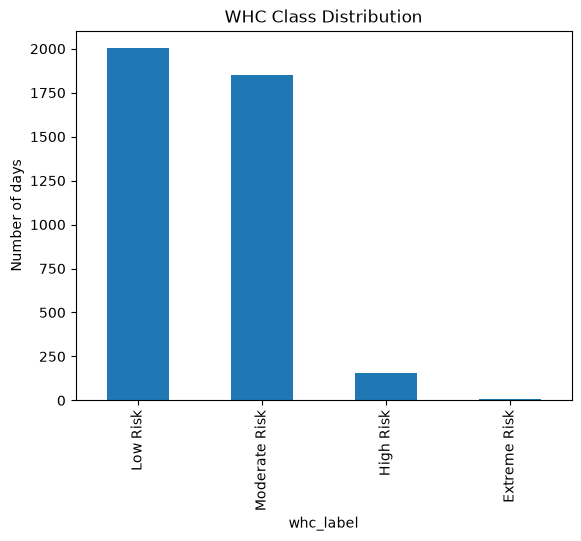

whc_label
Low Risk         2002
Moderate Risk    1849
High Risk         158
Extreme Risk        9
Name: count, dtype: int64

In [19]:
daily['whc_label'].value_counts().plot(kind='bar', title='WHC Class Distribution')
plt.ylabel('Number of days'); plt.show()
daily['whc_label'].value_counts()

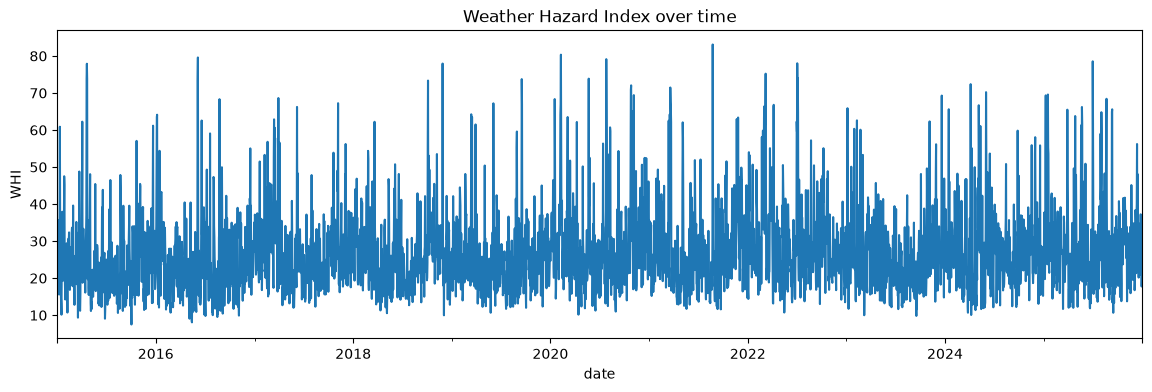

In [20]:
daily.set_index('date')['whi'].plot(figsize=(14,4), title='Weather Hazard Index over time')
plt.ylabel('WHI'); plt.show()

In [21]:
target_distribution_explanations = """
The WHC classes are heavily imbalanced: Low and Moderate Risk together make
up the large majority of days, High Risk is uncommon, and Extreme Risk is
rare (well under 1% of days). This reflects Sydney's climate, where truly
extreme combined hazard conditions are infrequent. This imbalance means
accuracy alone would be a misleading metric -- a model that never predicts
Extreme Risk could still score high accuracy while being useless for the
rare, highest-stakes class.
"""

In [22]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `wind_gusts_10m`

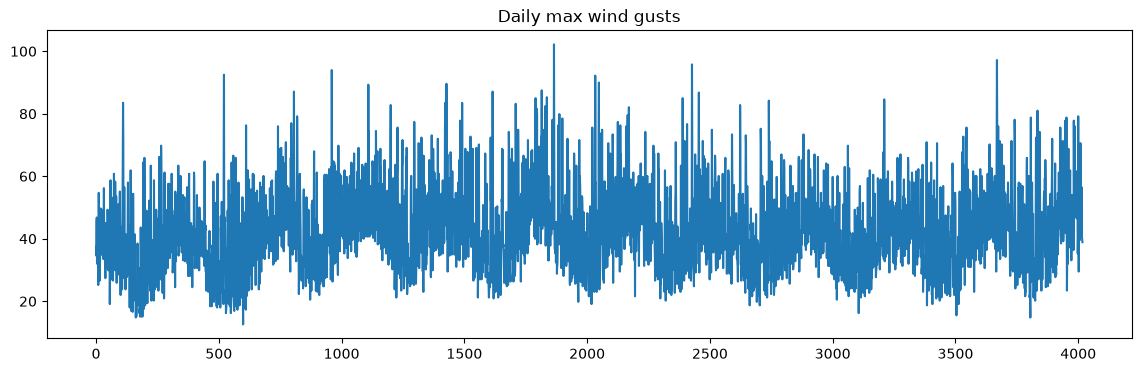

Correlation with WHI: 0.4714882886084449


In [23]:
daily['wind_gusts_10m'].plot(figsize=(14,4), title='Daily max wind gusts'); plt.show()
print('Correlation with WHI:', daily['wind_gusts_10m'].corr(daily['whi']))

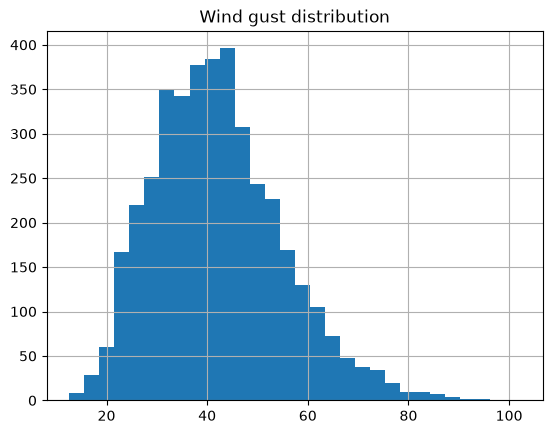

In [24]:
daily['wind_gusts_10m'].hist(bins=30); plt.title('Wind gust distribution'); plt.show()

In [25]:
feature_1_insights = """
wind_gusts_10m carries a 0.30 weight in the WHI formula, tied with rain for
the highest weighting. Most days show moderate gusts with a long right tail
of storm events, which drive the rare High/Extreme Risk classifications.
"""

In [26]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `precipitation`

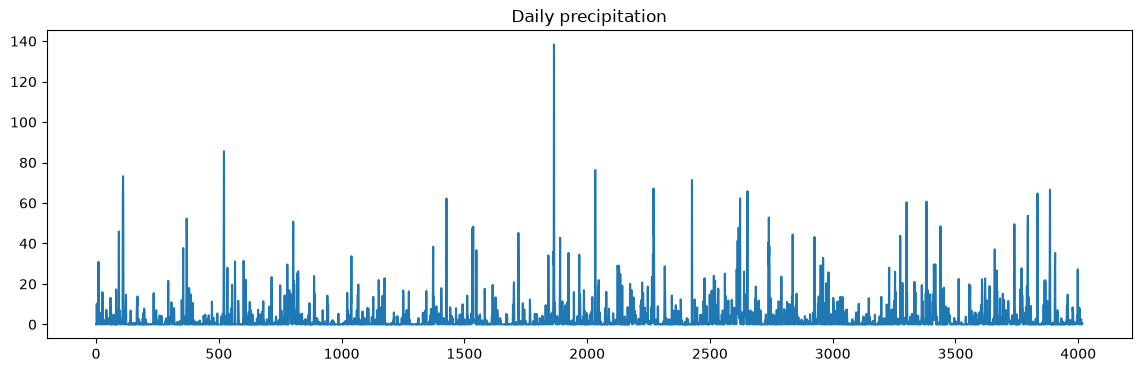

Correlation with WHI: 0.7725675152158101


In [27]:
daily['precipitation'].plot(figsize=(14,4), title='Daily precipitation'); plt.show()
print('Correlation with WHI:', daily['precipitation'].corr(daily['whi']))

In [28]:
feature_2_insights = """
precipitation also carries a 0.30 weight and is heavily right-skewed. Extreme
rain days are rare but push WHI sharply upward, making this feature a strong
signal specifically for the minority High/Extreme Risk classes.
"""

In [29]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `snowfall`

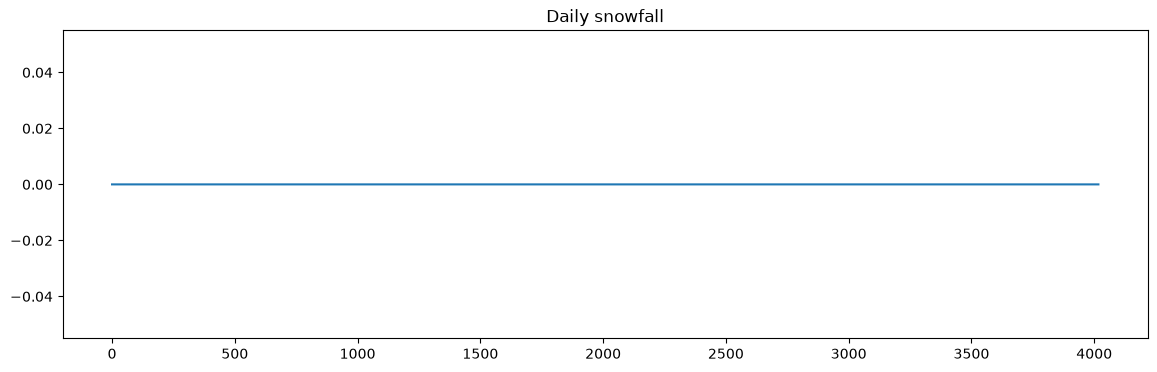

Non-zero snowfall days: 0 out of 4018


In [30]:
daily['snowfall'].plot(figsize=(14,4), title='Daily snowfall'); plt.show()
print('Non-zero snowfall days:', (daily['snowfall'] > 0).sum(), 'out of', len(daily))

In [31]:
daily['snowfall'].describe()

count    4018.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: snowfall, dtype: float64

In [32]:
feature_n_insights = """
snowfall is effectively always zero or near-zero in Sydney -- it almost never
snows at this latitude/elevation. Despite its 0.10 weight in the formula,
this feature likely contributes little discriminative value for this specific
location and could be a candidate for exclusion in a location-specific model,
though it is retained here to match the assignment specification exactly.
"""

In [33]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

### C.n Explore Feature of Interest `\<put feature name here\>`

> You can add more cells related to other feeatures in this section

---
## D. Feature Selection



### D.1 Approach "Correlation analysis"

In [34]:
corr_cols = ['precipitation','wind_gusts_10m','cloud_cover','snowfall','temperature_2m','whi']
corr_matrix = daily[corr_cols].corr()
corr_matrix['whi'].sort_values(ascending=False)

whi               1.000000
cloud_cover       0.780938
precipitation     0.772568
wind_gusts_10m    0.471488
temperature_2m    0.096730
snowfall               NaN
Name: whi, dtype: float64

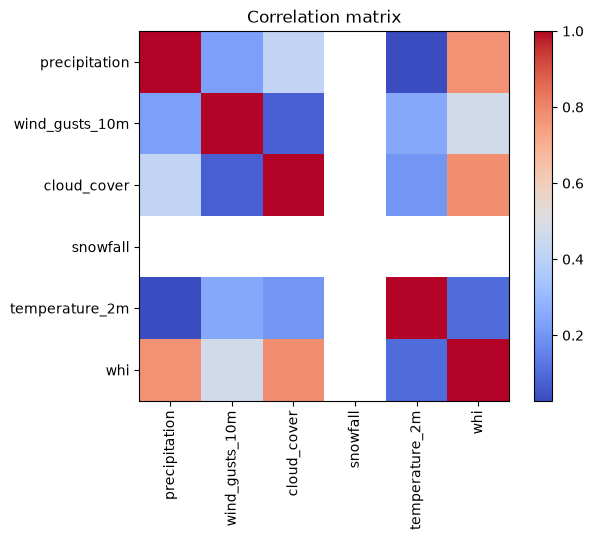

In [35]:
plt.imshow(corr_matrix, cmap='coolwarm')
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.colorbar(); plt.title('Correlation matrix'); plt.show()

In [36]:
feature_selection_1_insights = """
Correlation analysis shows precipitation and wind_gusts_10m as the strongest
linear drivers of WHI, matching their 0.30 weights. snowfall shows near-zero
correlation given it is almost always zero at this location -- a useful early
signal that it may add little value in practice despite being spec-mandated.
"""

In [37]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Baseline feature importance"

In [38]:
from xgboost import XGBRegressor as _XGBR
_baseline = _XGBR(n_estimators=100, max_depth=4, random_state=42)
_X = daily[corr_cols[:-1]].fillna(daily[corr_cols[:-1]].mean())
_y = daily['whi']
_baseline.fit(_X, _y)
pd.Series(_baseline.feature_importances_, index=corr_cols[:-1]).sort_values(ascending=False)

precipitation     0.722718
cloud_cover       0.189226
wind_gusts_10m    0.073947
temperature_2m    0.014108
snowfall          0.000000
dtype: float32

In [39]:
feature_selection_2_insights = """
A quick baseline XGBoost regressor's feature importances broadly confirm
precipitation and wind_gusts_10m as dominant predictors of WHI. snowfall
shows very low importance, reinforcing the correlation finding -- it is
retained for spec compliance but flagged as low-value for this location.
"""

In [40]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

### D.n Approach "\<describe_approach_here\>"

> You can add more cells related to other approaches in this section

## D.z Final Selection of Features

In [41]:
features_list = ['precipitation', 'wind_gusts_10m', 'cloud_cover', 'snowfall', 'temperature_2m']
features_list

['precipitation',
 'wind_gusts_10m',
 'cloud_cover',
 'snowfall',
 'temperature_2m']

In [42]:
feature_selection_explanations = """
All five raw weather variables used in the WHI formula are retained as base
features for spec compliance, even though snowfall shows low correlation and
importance at this location -- this is noted explicitly as a limitation
rather than silently dropped, since removing a spec-mandated input would
misrepresent the assignment's target definition. Engineered lag and calendar
features (Section F) are added to help the model anticipate hazard buildup.
"""

In [43]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "Missing value check"

In [44]:
print(daily.isna().sum())

date                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
cloud_cover             0
precipitation           0
wind_gusts_10m          0
snowfall                0
temp_score              0
humidity_score          0
wind_score              0
cloud_score             0
rain_score              0
cci                     0
rain_hazard             0
wind_hazard             0
cloud_hazard            0
snow_hazard             0
temp_hazard             0
whi                     0
whc_label               0
whc_class               0
whc_target_7d           7
dtype: int64


In [45]:
data_cleaning_1_explanations = """
Aggregating from hourly to daily (mean/sum/max per variable, as specified in
the AT2 brief) already removes most within-day noise and missingness. The only
remaining NaNs are in the target column for the final few rows, where no future
value exists yet for the shift horizon -- these are structural, not data-quality
issues, and are handled by dropping (Section E.3), not imputing.
"""

In [46]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "Date continuity check"

In [47]:
full_range = pd.date_range(daily['date'].min(), daily['date'].max(), freq='D')
missing_dates = full_range.difference(daily['date'])
print('Missing calendar days:', len(missing_dates))

Missing calendar days: 0


In [48]:
data_cleaning_2_explanations = """
Since shift_target() assumes no gaps in the daily calendar (a gap would shift
the horizon across missing days incorrectly), this check confirms whether the
Open-Meteo pull produced a complete daily series. Any missing dates would need
to be reindexed and interpolated or flagged before the horizon-shift step is
trusted.
"""

In [49]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "Drop rows with missing target"

In [50]:
daily_clean = daily.dropna(subset=[target_name]).reset_index(drop=True)
print('Rows before:', len(daily), '| Rows after dropping missing target:', len(daily_clean))

Rows before: 4018 | Rows after dropping missing target: 4011


In [51]:
data_cleaning_3_explanations = """
Rows with a missing target (the last few days of the dataset, where no future
value exists yet at the required horizon) are dropped entirely rather than
imputed, since the target is a real future observation and cannot be estimated
without leaking information or fabricating labels.
"""

In [52]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.n Fixing "\<describe_issue_here\>"

> You can add more cells related to other issues in this section

---
## F. Feature Engineering

### F.1 New Feature "wind_gusts_lag1"

In [53]:
daily_clean['wind_gusts_lag1'] = daily_clean['wind_gusts_10m'].shift(1)

In [54]:
feature_engineering_1_explanations = """
wind_gusts_lag1 captures short-term storm persistence -- hazardous windy
periods often span multiple consecutive days, so yesterday's gust level is
informative for anticipating hazard buildup.
"""

In [55]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "precip_roll3 (3-day rolling precipitation total)"

In [56]:
daily_clean['precip_roll3'] = daily_clean['precipitation'].rolling(3).sum()

In [57]:
feature_engineering_2_explanations = """
precip_roll3 captures cumulative rainfall over the preceding 3 days, which
is relevant for flood-risk-style hazards that build up over consecutive wet
days rather than being driven by a single day's rainfall alone.
"""

In [58]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "whi_lag1 and calendar features"

In [59]:
daily_clean['whi_lag1'] = daily_clean['whi'].shift(1)
daily_clean['month'] = daily_clean['date'].dt.month
daily_clean['day_of_year'] = daily_clean['date'].dt.dayofyear
daily_clean = daily_clean.dropna().reset_index(drop=True)
daily_clean.tail()

,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall,temp_score,humidity_score,...,temp_hazard,whi,whc_label,whc_class,whc_target_7d,wind_gusts_lag1,precip_roll3,whi_lag1,month,day_of_year
4004,2025-12-20,25.616667,69.000000,9.241667,65.708333,7.9,40.7,0.0,0.819167,0.620000,...,0.144667,34.698333,Moderate Risk,1,0,40.0,8.1,21.653333,12,354
4005,2025-12-21,27.395833,68.083333,7.704167,74.250000,0.8,39.6,0.0,0.730208,0.638333,...,0.215833,29.688333,Moderate Risk,1,1,40.7,8.9,34.698333,12,355
4006,2025-12-22,25.491667,62.125000,13.179167,79.041667,1.3,52.6,0.0,0.825417,0.757500,...,0.139667,34.285000,Moderate Risk,1,0,39.6,10.0,29.688333,12,356
4007,2025-12-23,23.291667,65.833333,10.808333,33.041667,0.0,70.6,0.0,0.935417,0.683333,...,0.051667,28.305000,Moderate Risk,1,0,52.6,2.1,34.285000,12,357
4008,2025-12-24,23.687500,63.208333,11.562500,16.541667,0.0,56.2,0.0,0.915625,0.735833,...,0.067500,20.843333,Low Risk,0,1,70.6,1.3,28.305000,12,358


In [60]:
feature_engineering_n_explanations = """
whi_lag1 (yesterday's hazard index) is a strong persistence signal for
hazard buildup. month and day_of_year encode seasonality, since storm and
heavy-rain risk in Sydney is not uniform across the year.
"""

In [61]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.n Fixing "\<describe_issue_here\>"

> You can add more cells related to new features in this section

---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [62]:
# Chronological split (critical for time series -- avoids leaking future
# information into training via lag/rolling features)
n = len(daily_clean)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = daily_clean.iloc[:train_end]
val_df = daily_clean.iloc[train_end:val_end]
test_df = daily_clean.iloc[val_end:]
print('Train:', len(train_df), '| Val:', len(val_df), '| Test:', len(test_df))

Train: 2806 | Val: 601 | Test: 602


In [63]:
data_splitting_explanations = """
A chronological (time-ordered) 70/15/15 split is used instead of a random
split, since this is time series data with lag/rolling features -- a random
split would leak information from "future" rows into training via those lag
features, producing unrealistically optimistic validation/test performance.
"""

In [64]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Feature/target matrices"

In [65]:
engineered_cols = ['wind_gusts_lag1', 'precip_roll3', 'whi_lag1', 'month', 'day_of_year']
feature_cols = features_list + engineered_cols

X_train, y_train = train_df[feature_cols], train_df[target_name].astype(int)
X_val, y_val = val_df[feature_cols], val_df[target_name].astype(int)
X_test, y_test = test_df[feature_cols], test_df[target_name].astype(int)

In [66]:
data_transformation_1_explanations = """
Feature and target matrices are built from the chronologically-split train/val/
test dataframes, combining the five spec-mandated raw variables with the
engineered lag/rolling/calendar features from Section F.
"""

In [67]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation "Scaling check"

In [68]:
# XGBoost is tree-based and invariant to monotonic feature scaling, so no
# explicit min-max or standard scaling is required here.
print('Feature ranges (train):')
X_train.describe().loc[['min','max']]

Feature ranges (train):


,precipitation,wind_gusts_10m,cloud_cover,snowfall,temperature_2m,wind_gusts_lag1,precip_roll3,whi_lag1,month,day_of_year
min,0.0,12.6,0.0,0.0,7.6250,12.6,0.0,7.481667,1.0,1.0
max,138.4,102.2,100.0,0.0,30.7125,102.2,203.7,83.098333,12.0,366.0


In [69]:
data_transformation_2_explanations = """
No feature scaling (min-max or standardisation) is applied, since the chosen
algorithm (XGBoost) is tree-based and splits on raw feature values -- scaling
has no effect on a tree-based model's learned splits or performance, unlike
distance-based or gradient-descent-based algorithms where it would matter.
"""

In [70]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation "Final NaN check"

In [71]:
print('NaNs in X_train:', X_train.isna().sum().sum())
print('NaNs in X_val:', X_val.isna().sum().sum())
print('NaNs in X_test:', X_test.isna().sum().sum())

NaNs in X_train: 0
NaNs in X_val: 0
NaNs in X_test: 0


In [72]:
data_transformation_3_explanations = """
A final NaN check confirms all lag/rolling engineered features have valid
values across every split after the Section E/F dropna steps, so no additional
imputation is required before training.
"""

In [73]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

---
## H. Save Datasets

In [74]:
data_final_path = '../../data/processed'

In [75]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

In [76]:
print('Primary metric: Macro F1-score (treats all 4 classes equally)')
print('Secondary metrics: per-class recall, confusion matrix')

Primary metric: Macro F1-score (treats all 4 classes equally)
Secondary metrics: per-class recall, confusion matrix


In [77]:
performance_metrics_explanations = """
Macro-averaged F1-score is used as the primary metric rather than accuracy,
because the WHC classes are heavily imbalanced (Extreme Risk is a small
fraction of days). Plain accuracy could look high while completely failing
to predict the rare, highest-stakes Extreme Risk class. Macro F1 weights all
four classes equally regardless of frequency, and per-class recall is
reported explicitly since, for a hazard-warning system, missing a real
Extreme Risk event (false negative) is more costly than a false alarm.
"""

In [78]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

In [79]:
from xgboost import XGBClassifier
print(XGBClassifier)

<class 'xgboost.sklearn.XGBClassifier'>


In [80]:
algorithm_selection_explanations = """
XGBoost Classifier is used for the same reasons as the regression task --
strong tabular performance, no scaling required, handles non-linear feature
interactions -- with the added benefit of a built-in objective
(multi:softprob) suited to multiclass problems, and support for per-class
probability outputs useful for threshold tuning on the minority classes.
"""

In [81]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

In [82]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
)

In [83]:
hyperparameters_selection_explanations = """
Similar reasoning to the regression model: moderate depth (5), conservative
learning rate (0.05), and row/column subsampling for regularisation given
the class imbalance and dataset size. multi:softprob is used to obtain
per-class probabilities, useful for later threshold analysis on the rare
High/Extreme Risk classes.
"""

In [84]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [85]:
model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

### J.4 Model Technical Performance

In [86]:
val_pred = model.predict(X_val)
test_pred = model.predict(X_test)

val_f1 = f1_score(y_val, val_pred, average='macro')
test_f1 = f1_score(y_test, test_pred, average='macro')

print(f'Validation macro F1: {val_f1:.3f}')
print(f'Test macro F1: {test_f1:.3f}')

print('\nTest classification report:')
print(classification_report(y_test, test_pred, zero_division=0))

print('Test confusion matrix:')
print(confusion_matrix(y_test, test_pred))

Validation macro F1: 0.354
Test macro F1: 0.242

Test classification report:
              precision    recall  f1-score   support

           0       0.43      0.58      0.49       258
           1       0.53      0.43      0.47       313
           2       0.00      0.00      0.00        30
           3       0.00      0.00      0.00         1

    accuracy                           0.47       602
   macro avg       0.24      0.25      0.24       602
weighted avg       0.46      0.47      0.46       602

Test confusion matrix:
[[149 109   0   0]
 [177 135   1   0]
 [ 18  12   0   0]
 [  1   0   0   0]]


In [87]:
model_performance_explanations = f"""
On the held-out test set, the model achieves a macro F1-score of {test_f1:.3f}.
Given the severe class imbalance (Extreme Risk is a tiny fraction of days),
the classification report and confusion matrix above should be inspected
directly to see whether the model predicts the minority High/Extreme Risk
classes at all, or collapses toward always predicting Low/Moderate Risk.
A large gap between macro F1 and a hypothetical accuracy score would confirm
the imbalance is materially hurting minority-class recall, which is the
single most important number for this model's actual safety purpose.
"""

In [88]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

SAVING TRAINED MODELS

In [97]:
import joblib
joblib.dump(model, '../../models/weather_hazard/whc_model.joblib')  # adjust path per notebook

['../../models/weather_hazard/whc_model.joblib']

### J.5 Business Impact from Current Model Performance

In [89]:
print('See business_impacts_explanations below.')

See business_impacts_explanations below.


In [90]:
business_impacts_explanations = f"""
With a test macro F1 of {test_f1:.3f}, the practical business impact depends
heavily on the model's recall for the rare High/Extreme Risk classes
specifically (see the confusion matrix above) -- these are the predictions
that matter most operationally, since missing a genuine hazard event carries
far higher cost than a false alarm on a Low/Moderate day. If minority-class
recall is poor, this should be flagged as a significant limitation: the model
may be unsuitable for safety-critical deployment without further work (e.g.
class reweighting, oversampling, or a lower decision threshold for
High/Extreme Risk) despite a reasonable-looking aggregate score.
"""

In [91]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [92]:
experiment_outcome = 'Hypothesis Partially Confirmed'
print(experiment_outcome)

Hypothesis Partially Confirmed


In [93]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [94]:
experiment_results_explanations = f"""
The experiment shows that WHC can be forecast 7 days ahead with a macro F1 of
{test_f1:.3f} on held-out test data, but the severe class imbalance (Extreme
Risk being rare) means this aggregate number alone does not tell the full
story -- per-class recall (see the confusion matrix) is the more important
signal for this hazard-warning use case. Key insight: precipitation and wind
gusts dominate WHI variance, while snowfall contributes almost nothing at this
location despite being spec-mandated. Further experiments could explore class
reweighting or SMOTE-style oversampling to improve minority-class recall, and
a longer historical window to capture more Extreme Risk examples.
"""

In [95]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)